# Benchmarking experiment across methods

## 1. Creating the example model

In [1]:
import yaml
import pypsa
import numpy as np
import pandas as pd

from mga4all.examples import create_pypsa_network

In [2]:
# Load example PyPSA model that the config refers to
# n = pypsa.Network("example_model_pypsa.xlsx")
n = create_pypsa_network()

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'SciGrid-DE' has buses, carriers, generators, lines, loads, storage_units, transformers


In [3]:
n.set_snapshots(n.snapshots[0:56])

In [4]:
# Set the desired solver options
pypsa.options.params.optimize.solver_name = "gurobi"
pypsa.options.params.optimize.solver_options = {
    'Method': 2,  # Use the barrier algorithm
    'Crossover': 0,
}

In [5]:
# Find cost-optimal solution
n.optimize(log_to_console=False);

/tmp/ipykernel_64204/2238090962.py:2: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(log_to_console=False);
Index(['line'], dtype='object', name='name')
Index(['line'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False
INFO:linopy.io: Writing time: 0.07s


Set parameter Username


INFO:gurobipy:Set parameter Username


Academic license - for non-commercial use only - expires 2027-09-07


INFO:gurobipy:Academic license - for non-commercial use only - expires 2027-09-07


...

INFO:gurobipy:Set parameter Method to value 2


Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Linux Mint 22")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i7-10610U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 4 physical cores, 8 logical processors, using up to 8 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 688 rows, 296 columns and 1324 nonzeros
INFO:gurobipy:Model fingerprint: 0xd41ae2e6
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 5e+00]
INFO:gurobipy:  Objective range  [4e+02, 2e+03]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 1e+03]
INFO:gurobipy:Presolve removed 124 rows and 332 columns
INFO:gurobipy:Presolve time: 0.01s
INFO:gurobipy:Presolved: 172 rows, 356 columns, 1572 nonzeros


In [6]:
from mga4all.exploration_metrics import mean_of_shannon_of_projections, volume_estimation_by_shadow_addition
n_alternatives = 80
methods = ['random_directions_spatial', 'random_directions', 'hop_skip_jump', 'spores', 'spores_adaptive']
shannon_df = pd.DataFrame(index=range(0,n_alternatives+1), columns=methods).astype(float).fillna(0)
vesa_df = pd.DataFrame(index=range(0,n_alternatives+1), columns=methods).astype(float).fillna(0)

In [7]:
shannon_df.head()

,random_directions_spatial,random_directions,hop_skip_jump,spores,spores_adaptive
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0


## 2. Random-direction spatial algorithm

In [8]:
from mga4all.validate import RandomDirectionsConfig

# Load configuration file
with open("../../configs/method_benchmarkingrandom_directions_spatial.yaml") as yf:
    config = RandomDirectionsConfig.model_validate(yaml.safe_load(yf))

In [9]:
from mga4all.mga_random_directions import random_directions_algorithm

In [10]:
name_run = 'random_directions_spatial'
mga_spatial_alternatives, mga_alternatives, mga_weights = random_directions_algorithm(config, n)

Index(['line'], dtype='object', name='name')
Index(['line'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False
INFO:linopy.io: Writing time: 0.08s


Technologies [] not found in the model
Set parameter Username


INFO:gurobipy:Set parameter Username


Academic license - for non-commercial use only - expires 2027-09-07


INFO:gurobipy:Academic license - for non-commercial use only - expires 2027-09-07


...

INFO:gurobipy:Set parameter Method to value 2


Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Linux Mint 22")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i7-10610U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 4 physical cores, 8 logical processors, using up to 8 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 689 rows, 296 columns and 1332 nonzeros
INFO:gurobipy:Model fingerprint: 0x5eccaf2b
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 2e+03]
INFO:gurobipy:  Objective range  [1e-01, 9e-01]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 7e+05]
INFO:gurobipy:Presolve removed 124 rows and 334 columns
INFO:gurobipy:Presolve time: 0.00s
INFO:gurobipy:Presolved: 172 rows, 355 columns, 1578 nonzeros


In [11]:
from mga4all.exploration_metrics import exploration_metrics_progression
from mga4all.model_interface_pypsa import extract_capacity_bounds

# Let's first extract the feasibility bounds of the model, needed for the Shannon index.
bounds_spatial, bounds_aggregate = extract_capacity_bounds(n, config)

Technologies [] not found in the model


In [12]:
import copy
BOUNDS_SPATIAL = copy.deepcopy(bounds_spatial)
BOUNDS_AGGREGATE = copy.deepcopy(bounds_aggregate) # The bounds are the same across algorithms, since they are a constant property of the model

In [13]:
for alt in mga_spatial_alternatives.columns:
    shannon_df.loc[alt,name_run] = mean_of_shannon_of_projections(mga_spatial_alternatives.iloc[:,0:alt+1], lb=BOUNDS_SPATIAL['lb'], ub=BOUNDS_SPATIAL['ub'])
    vesa_df.loc[alt,name_run] = volume_estimation_by_shadow_addition(mga_spatial_alternatives.iloc[:,0:alt+1])

In [14]:
vesa_df.head()

,random_directions_spatial,random_directions,hop_skip_jump,spores,spores_adaptive
0,0.000000e+00,0.0,0.0,0.0,0.0
1,9.094947e-13,0.0,0.0,0.0,0.0
2,1.184762e+05,0.0,0.0,0.0,0.0
3,2.411637e+05,0.0,0.0,0.0,0.0
4,3.129695e+05,0.0,0.0,0.0,0.0


## 3. Random-direction regular algorithm

In [15]:
# Load configuration file
with open("../../configs/method_benchmarkingrandom_directions.yaml") as yf:
    config = RandomDirectionsConfig.model_validate(yaml.safe_load(yf))

In [16]:
name_run = 'random_directions'
mga_spatial_alternatives, mga_alternatives, mga_weights = random_directions_algorithm(config, n)

Index(['line'], dtype='object', name='name')
Index(['line'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False
INFO:linopy.io: Writing time: 0.06s


Technologies [] not found in the model
Set parameter Username


INFO:gurobipy:Set parameter Username


Academic license - for non-commercial use only - expires 2027-09-07


INFO:gurobipy:Academic license - for non-commercial use only - expires 2027-09-07


...

INFO:gurobipy:Set parameter Method to value 2


Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Linux Mint 22")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i7-10610U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 4 physical cores, 8 logical processors, using up to 8 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 689 rows, 296 columns and 1332 nonzeros
INFO:gurobipy:Model fingerprint: 0x1405a092
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 2e+03]
INFO:gurobipy:  Objective range  [1e-01, 8e-01]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 7e+05]
INFO:gurobipy:Presolve removed 124 rows and 334 columns
INFO:gurobipy:Presolve time: 0.01s
INFO:gurobipy:Presolved: 172 rows, 355 columns, 1578 nonzeros


In [17]:
for alt in mga_spatial_alternatives.columns:
    shannon_df.loc[alt,name_run] = mean_of_shannon_of_projections(mga_spatial_alternatives.iloc[:,0:alt+1], lb=BOUNDS_SPATIAL['lb'], ub=BOUNDS_SPATIAL['ub'])
    vesa_df.loc[alt,name_run] = volume_estimation_by_shadow_addition(mga_spatial_alternatives.iloc[:,0:alt+1])

## 4. Hop-Skip-Jump algorithm

In [18]:
from mga4all.validate import HopSkipJumpConfig

# Load configuration file
with open("../../configs/method_benchmarkinghop_skip_jump.yaml") as yf:
    config = HopSkipJumpConfig.model_validate(yaml.safe_load(yf))

In [19]:
# Define a 'noise threshold' to avoid penalising small capacity deployment
noise_threshold = int(n.statistics.optimal_capacity().min())
noise_threshold 

44

In [20]:
from mga4all.mga_hop_skip_jump import hop_skip_jump_algorithm
name_run = 'hop_skip_jump'
mga_spatial_alternatives, mga_alternatives, mga_weights = hop_skip_jump_algorithm(config, n, noise_threshold)

Index(['line'], dtype='object', name='name')
Index(['line'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False


Technologies [] not found in the model


INFO:linopy.io: Writing time: 0.19s


Set parameter Username


INFO:gurobipy:Set parameter Username


...

INFO:gurobipy:Set parameter Method to value 2


Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Linux Mint 22")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i7-10610U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 4 physical cores, 8 logical processors, using up to 8 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 689 rows, 296 columns and 1332 nonzeros
INFO:gurobipy:Model fingerprint: 0x41283ad0
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 2e+03]
INFO:gurobipy:  Objective range  [2e+00, 8e+01]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 7e+05]
INFO:gurobipy:Presolve removed 124 rows and 334 columns
INFO:gurobipy:Presolve time: 0.00s
INFO:gurobipy:Presolved: 172 rows, 355 columns, 1578 nonzeros


In [21]:
for alt in mga_spatial_alternatives.columns:
    shannon_df.loc[alt,name_run] = mean_of_shannon_of_projections(mga_spatial_alternatives.iloc[:,0:alt+1], lb=BOUNDS_SPATIAL['lb'], ub=BOUNDS_SPATIAL['ub'])
    vesa_df.loc[alt,name_run] = volume_estimation_by_shadow_addition(mga_spatial_alternatives.iloc[:,0:alt+1])

## 5. SPORES algorithm

In [22]:
from mga4all.validate import SPORESConfig
runs = ['maxwind', 'minwind', 'maxsolar', 'minsolar', 'maxgas', 'mingas', 'maxbat', 'minbat']

mga_spatial_alternatives_macro = {}

from mga4all.mga_spores import spores_algorithm
for name_run in runs:
    with open("../../configs/method_benchmarkingspores_{}.yaml".format(name_run)) as yf:
        config = SPORESConfig.model_validate(yaml.safe_load(yf))
        mga_spatial_alternatives, mga_alternatives, mga_weights = spores_algorithm(config, n, adaptive=False)
        mga_spatial_alternatives_macro['spores_{}'.format(name_run)] = mga_spatial_alternatives.copy()

Index(['line'], dtype='object', name='name')
Index(['line'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False


Technologies [] not found in the model


INFO:linopy.io: Writing time: 0.09s


Set parameter Username


INFO:gurobipy:Set parameter Username


...

INFO:gurobipy:Set parameter Method to value 2


Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Linux Mint 22")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i7-10610U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 4 physical cores, 8 logical processors, using up to 8 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 689 rows, 296 columns and 1332 nonzeros
INFO:gurobipy:Model fingerprint: 0x1a3ea8a3
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 2e+03]
INFO:gurobipy:  Objective range  [2e-04, 6e-01]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 7e+05]
INFO:gurobipy:Presolve removed 124 rows and 334 columns
INFO:gurobipy:Presolve time: 0.00s
INFO:gurobipy:Presolved: 172 rows, 355 columns, 1578 nonzeros


In [23]:
dfs = list(mga_spatial_alternatives_macro.values())

# Keep the common solution (column 0) only from the first DataFrame
combined = pd.concat(
    [dfs[0]] + [df.drop(columns=0) for df in dfs[1:]],
    axis=1,
    ignore_index=True
)

combined.columns = range(combined.shape[1])

In [24]:
name_run = 'spores'

for alt in combined.columns:
    shannon_df.loc[alt,name_run] = mean_of_shannon_of_projections(combined.iloc[:,0:alt+1], lb=BOUNDS_SPATIAL['lb'], ub=BOUNDS_SPATIAL['ub'])
    vesa_df.loc[alt,name_run] = volume_estimation_by_shadow_addition(combined.iloc[:,0:alt+1])

## 6. SPORES-adaptive algorithm

In [25]:
from mga4all.validate import SPORESConfig
runs = ['maxwind', 'minwind', 'maxsolar', 'minsolar', 'maxgas', 'mingas', 'maxbat', 'minbat']

mga_spatial_alternatives_macro = {}

for name_run in runs:
    with open("../../configs/method_benchmarkingspores_{}.yaml".format(name_run)) as yf:
        config = SPORESConfig.model_validate(yaml.safe_load(yf))
        mga_spatial_alternatives, mga_alternatives, mga_weights = spores_algorithm(config, n, adaptive=True)
        mga_spatial_alternatives_macro['spores_{}'.format(name_run)] = mga_spatial_alternatives.copy()

Index(['line'], dtype='object', name='name')
Index(['line'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False


Technologies [] not found in the model


INFO:linopy.io: Writing time: 0.07s


Set parameter Username


INFO:gurobipy:Set parameter Username


...

INFO:gurobipy:Set parameter Method to value 2


Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Linux Mint 22")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i7-10610U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 4 physical cores, 8 logical processors, using up to 8 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 689 rows, 296 columns and 1332 nonzeros
INFO:gurobipy:Model fingerprint: 0x83763abb
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 2e+03]
INFO:gurobipy:  Objective range  [9e-02, 5e-01]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 7e+05]
INFO:gurobipy:Presolve removed 124 rows and 334 columns
INFO:gurobipy:Presolve time: 0.00s
INFO:gurobipy:Presolved: 172 rows, 355 columns, 1578 nonzeros


In [26]:
dfs = list(mga_spatial_alternatives_macro.values())

# Keep the common solution (column 0) only from the first DataFrame
combined = pd.concat(
    [dfs[0]] + [df.drop(columns=0) for df in dfs[1:]],
    axis=1,
    ignore_index=True
)

combined.columns = range(combined.shape[1])

In [27]:
name_run = 'spores_adaptive'

for alt in combined.columns:
    shannon_df.loc[alt,name_run] = mean_of_shannon_of_projections(combined.iloc[:,0:alt+1], lb=BOUNDS_SPATIAL['lb'], ub=BOUNDS_SPATIAL['ub'])
    vesa_df.loc[alt,name_run] = volume_estimation_by_shadow_addition(combined.iloc[:,0:alt+1])

## 7. Assessment

<Axes: >

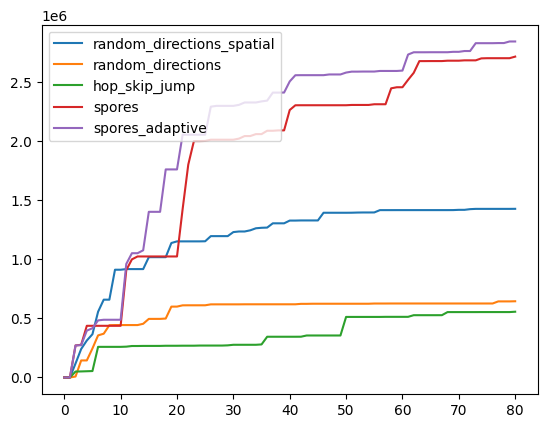

In [28]:
vesa_df.round(2).plot()

<Axes: >

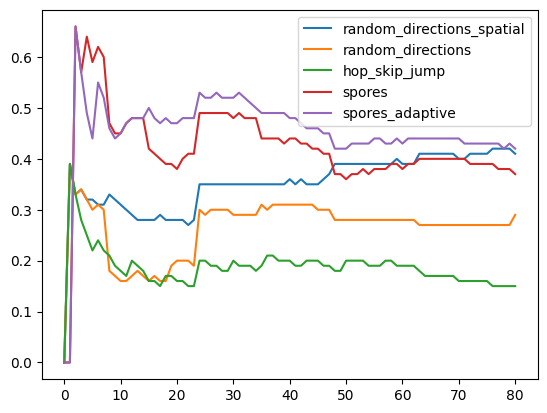

In [29]:
shannon_df.round(2).plot()